In [1]:
import pandas as pd
import numpy as np
import lifelines as ll
import sksurv as sks
import matplotlib.pyplot as plt
from bart_survival import surv_bart as sb


import lifelines as ll
from lifelines import KaplanMeierFitter
import subprocess
import threading as th
import multiprocessing as mp
import sys
sys.path.append("../src/")
import sim_adj as sm
import arviz as az

In [7]:
def get_sim(rng, N, type, x_vars, VAR_CLASS, VAR_PROB, scale_f, shape_f, cens_scale):
    x_mat = sm.get_x_matrix(
        N = N,
        x_vars = x_vars, 
        VAR_CLASS=VAR_CLASS,
        VAR_PROB= VAR_PROB,
        rng = rng
    )

    event_dict, sv_true, sv_scale_true = sm.simulate_survival(
        x_mat = x_mat,
        scale_f=scale_f,
        shape_f=shape_f,
        cens_scale=cens_scale,
        rng = rng
    )
    
    return type, x_mat, event_dict, sv_true, sv_scale_true


def get_quant_times(sv_true_c, sv_true, quant=[0.9,0.75,0.5,0.25,0.1]):
	qnt_t = []
	for i in quant:
		tmp = np.abs(sv_true_c - i)
		idx = tmp == tmp.min()
		qnt_t.append(sv_true["true_times"][idx])
	return np.array(qnt_t)

def get_quant_events(qnt_t, event):
	q = np.array(qnt_t)
	et_ = event["t_event"].copy()
	et_out = event["t_event"].copy()
	es_out = event["status"].copy()
	for i in range(q.shape[0]):
		if i == 0:
			msk = et_<=q[i]
			et_out[msk] = q[i]
			# print(np.unique(et_out))
		else:
			msk = (q[i-1] < et_) & (et_ <= q[i])
			et_out[msk] = q[i]
			# print(np.unique(et_out))
			if i == q.shape[0]-1:
				msk = et_ > q[i]
				et_out[msk] = q[i]
				es_out[msk] = 0

	return {"t_event":et_out, "status":es_out}

def ed_sub(event_dict, x_mat, x_val):
    msk = x_mat[:,0] == x_val
    ed_out = {
        "t_event":event_dict["t_event"][msk],
        "status":event_dict["status"][msk]
    }
    uniq_t = np.unique(ed_out["t_event"])
    return ed_out, uniq_t

def ci_at_times(ci, k_t, uniq_t):
    k_s = k_t.shape[0]
    uniq_idx =np.arange(uniq_t.shape[0])
    out = np.zeros(shape=(2,uniq_t.shape[0]))
    for i in range(k_s):
        if i == k_s-1:
            msk = uniq_idx[uniq_t >= k_t[i]]
        else:
            lwr = k_t[i]
            upr = k_t[i+1]
            msk = uniq_idx[(lwr<=uniq_t) & (uniq_t < upr)]
        out[:,msk] = ci[:,i].reshape(-1,1)
    return out

def twopop_kpm(event_dict, uniq_t):
    kpm = ll.KaplanMeierFitter()
    kpm.fit(durations=event_dict["t_event"], event_observed=event_dict["status"])
    k1_a = kpm.survival_function_at_times(uniq_t).to_numpy()
    k1_ci = kpm.confidence_interval_survival_function_.values[1:,:].T
    k_t = kpm.timeline[1:]
    ci_a = ci_at_times(k1_ci, k_t, uniq_t)
    return k1_a, ci_a, uniq_t

def pb_sb_sub(sv_prob, msk):
    sv = sv_prob["sv"][:,msk,:]
    sv_m = sv_prob["sv"][:,msk,:].mean(0)
    sv_q = np.quantile(sv_prob["sv"][:,msk,:], [0.025,0.975], axis=0)    
    # sv_q = np.quantile(sv_prob["sv"][:,msk,:], [0.01,0.99], axis=0)    
    return sv, sv_m, sv_q

def get_py_bart_surv2(x_mat, event_dict, model_dict, sampler_dict, adj_weights=False, w_factor = 1):
    # event_dict = day_to_idx(event_dict)
    # print(event_dict)
    trn = sb.get_surv_pre_train(y_time = event_dict["t_event"], y_status=event_dict["status"], x = x_mat, weight=None)

    # print("trn\n", trn["x"])    
    de = np.unique(event_dict["t_event"])

    if adj_weights:
        ww = np.unique(trn["x"][:,0], return_counts=True)
        # for i in range(ww[0].shape[0]):
        #     tmp = (((max(ww[1]) // ww[1][i])-1) * w_factor) + 1
        #     trn["w"][trn["x"][:,0]==ww[0][i]] = tmp
        trn["w"][trn["x"][:,0]==ww[0][-1]] = 1 + w_factor
        print("w ", np.unique(trn["w"]))
    print("sum")
    print(trn["y"][(trn["x"][:,1]==0) & (trn["x"][:,0]==de[-1])].sum())
    print(trn["y"][(trn["x"][:,1]==0) & (trn["x"][:,0]==de[-1])].shape)
    print(trn["y"][(trn["x"][:,1]==1) & (trn["x"][:,0]==de[-1])].sum())
    print(trn["y"][(trn["x"][:,1]==1) & (trn["x"][:,0]==de[-1])].shape)
    # trn["w"][trn["x"][:,0]==de[-1]] = 60
    # trn["w"][trn["x"][:,0]==de[-2]] = 2
    # print(de[-2])
    
    post_test = sb.get_posterior_test(y_status=event_dict["status"], y_time=event_dict["t_event"], x=x_mat)
    small_post_x = np.unique(post_test["post_x"][:,0]).reshape(-1,1)
    xs = np.hstack([np.repeat(0, small_post_x.shape[0]), np.repeat(1, small_post_x.shape[0])])
    small_coords = np.hstack([np.repeat(0, small_post_x.shape[0]), np.repeat(1, small_post_x.shape[0]), ])
    small_post_x = np.vstack([small_post_x, small_post_x])
    small_post_x = np.hstack([small_post_x, xs.reshape(-1,1)])

    # return trn, post_test, small_post_x, small_coords
    BSM = sb.BartSurvModel(model_config=model_dict, sampler_config=sampler_dict)
    
    # fit with just the time column
    BSM.fit(y=trn["y"], X=trn["x"], weights=trn["w"], coords = trn["coord"], random_seed=99)
    post1 = BSM.sample_posterior_predictive(X_pred=small_post_x, coords=small_coords)
    sv_prob = sb.get_sv_prob(post1)

    sv_1 = pb_sb_sub(sv_prob, 0)
    sv_2 = pb_sb_sub(sv_prob, 1)
    uniq_t = BSM.uniq_times
    hdi_lh, ci_lh = get_hdi_ci_2(sv_prob)
    hdi_1 = hdi_lh[0].T
    hdi_2 = hdi_lh[1].T
    
    del BSM
    childs = mp.active_children()
    for child in childs:
        child.kill()
    return (sv_1[0], sv_1[1], sv_1[2], hdi_1), (sv_2[0], sv_2[1], sv_2[2], hdi_2), uniq_t


def get_hdi_ci_2(pb_sv):
    s1 = pb_sv["sv"].shape[0]
    s2 = pb_sv["sv"].shape[1]
    s3 = pb_sv["sv"].shape[2]
    hdi_pre = az.convert_to_dataset(pb_sv["sv"].reshape(1,s1,s2,s3))
    #low-high
    hdi_lh = az.hdi(hdi_pre, hdi_prob=.95).x.values
    # low-high
    ci_lh = np.quantile(pb_sv["sv"], [0.025, 0.975], 0)
    return hdi_lh, ci_lh

def day_to_idx(event_dict):
    idx = np.unique(event_dict["t_event"])
    for i in range(idx.shape[0]):
        event_dict["t_event"][event_dict["t_event"] == idx[i]] = i
    return event_dict

def check_array(v):
    if type(v) == list:
        v = np.array(v)
    return v

def rmse(true, est):
    true = check_array(true)
    est = check_array(est)
    # out = np.sqrt(np.power((true - est),2))
    out = np.sqrt(np.power((true - est),2).mean(0))
    return out

def bias(true, est):
    true = check_array(true)
    est = check_array(est)
    # out = (true-est)
    out = (true-est).mean(0)
    return out

# def coverage(true, ci_est, calc = True):
#     true = check_array(true)
#     ci_est = check_array(ci_est)

#     l = np.round(ci_est[:,0,:],4)
#     u = np.round(ci_est[:,1,:],4)
#     true = np.round(true, 4)
#     out = []
#     for i in range(true.shape[1]):
#         z = (l[:,i] <= true[:,i]) & (true[:,i] <= u[:,i])
#         out.append(z)
#     out = np.array(out).T
#     if calc:
#         return out.sum(0)/out.shape[0]
#     else:
#         return out

def coverage(true, ci_est):
    out = []
    for i in range(true.shape[0]):
        if (np.round(ci_est[0,i],3) <= np.round(true[i],3)) & (np.round(true[i],3) <= np.round(ci_est[1,i],3)):
            out.append(1)
        else:
            out.append(0)
    return out

In [3]:
def runner(seed, n, adj_weights, w_factor):
    rng = np.random.default_rng(seed)
    n = 400

    simple_2_1 = {
        "type": "Simple, 2 group, 20% cens",
        "x_vars": 1, 
        "VAR_CLASS": [2],
        "VAR_PROB":[.5],
        "scale_f": "12 - .5 *x_mat[:,0]",
        "shape_f": "1.2 + 1 *x_mat[:,0]",
        "cens_scale":5.9
        # "cens_scale":1.1
    }

    # Cond 1
    SPLIT_RULES1 =  [
        "pmb.ContinuousSplitRule()", 
        # "pmb.ContinuousSplitRule()", 
        "pmb.OneHotSplitRule()"
    ]
    MODEL_DICT1 = {"trees": 50,
        "split_rules": SPLIT_RULES1
    }
    SAMPLER_DICT1 = {
        "draws": 200,
        "tune": 100,
        "cores": 12,
        "chains": 12,
        "compute_convergence_checks": False,
        # "pgbart":{
                    # "num_particles":5,
                    # "batch":(.1,.1)
                # }
    }

    model_dict = MODEL_DICT1
    sampler_dict = SAMPLER_DICT1


    scenario, x_mat, event_dict, sv_true, sv_scale_true = get_sim(rng, n, **simple_2_1)
    print(event_dict["status"].mean())

    sv_true_mean = sv_true["sv_true"].mean(0)
    qnt_t = get_quant_times(sv_true_c=sv_true_mean, sv_true= sv_true).flatten()
    print(qnt_t)
    event_dict = get_quant_events(qnt_t=qnt_t, event=event_dict)

    x_tst, x_tst_idx = np.unique(x_mat, return_index=True)
    cens_perc = event_dict["status"][event_dict["status"] == 0].shape[0]/event_dict["status"].shape[0]
        
    # get uniq times and quantiles as indexes
    uniq_t = np.unique(event_dict["t_event"]) 
    print(uniq_t)
        
    sv_true_r0 = sv_true["sv_true"][int(x_tst_idx[0]),:]
    sv_true_r0 = sv_true_r0[qnt_t.astype("int") - 1]
    sv_true_r1 = sv_true["sv_true"][int(x_tst_idx[1]),:]
    sv_true_r1 = sv_true_r1[qnt_t.astype("int") - 1]
    # x_tst_idx


    ed1, uniq_t1 = ed_sub(event_dict, x_mat, 0)
    ed2, uniq_t2 = ed_sub(event_dict, x_mat, 1)
    k_sv1 = twopop_kpm(ed1, uniq_t)
    k_sv2 = twopop_kpm(ed2, uniq_t)


    pb_sv = get_py_bart_surv2(x_mat, event_dict, model_dict, sampler_dict, adj_weights, w_factor)
    # pb_sv_m = pb_sv["sv"].mean(1).mean(0)
    # hdi, ci = get_hdi_ci_2(pb_sv)
    return sv_true_r0, sv_true_r1, pb_sv, k_sv1, k_sv2


mean shape 1.7424999999999995
mean scale 11.72875
49.0
mean time draws 10.431878811571817
cens mean 69.5175
0.8725
[ 3  6  9 14 19]
[ 3.  6.  9. 14. 19.]
w  [1. 2. 4.]
sum
23.0
(44, 1)
34.0
(42, 1)


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(


Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 100 tune and 200 draw iterations (1_200 + 2_400 draws total) took 7 seconds.
Sampling: [f]


Output()

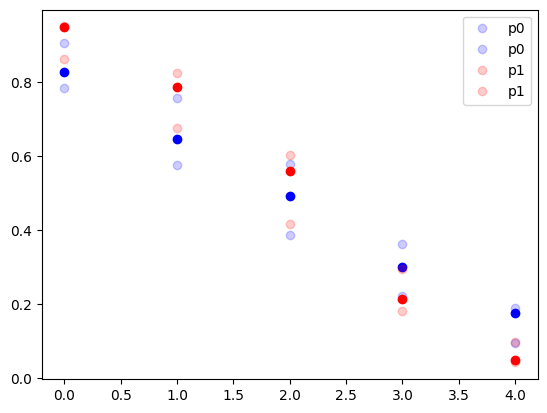

mean shape 1.6749999999999994
mean scale 11.7625
49.0
mean time draws 10.091593995668966
cens mean 72.745
0.8575
[ 3  5  9 14 20]
[ 3.  5.  9. 14. 20.]
w  [1. 2. 5.]
sum
20.0
(42, 1)
30.0
(32, 1)


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 100 tune and 200 draw iterations (1_200 + 2_400 draws total) took 6 seconds.
Sampling: [f]


Output()

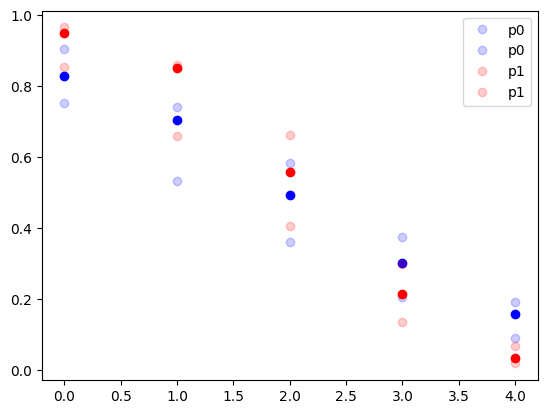

mean shape 1.6824999999999994
mean scale 11.75875
49.0
mean time draws 10.55236591921271
cens mean 73.77
0.905
[ 3  5  9 14 20]
[ 3.  5.  9. 14. 20.]
w  [1. 2. 4.]
sum
23.0
(53, 1)
40.0
(44, 1)


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 100 tune and 200 draw iterations (1_200 + 2_400 draws total) took 6 seconds.
Sampling: [f]


Output()

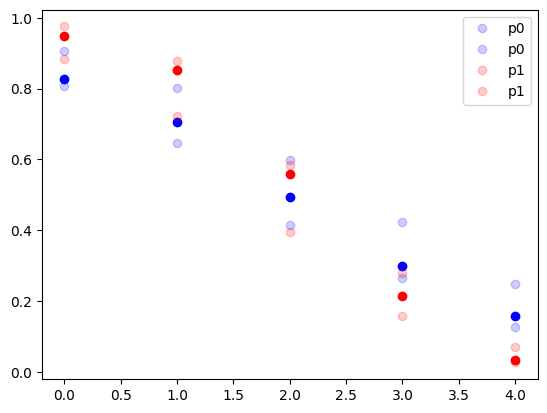

mean shape 1.7224999999999997
mean scale 11.73875
49.0
mean time draws 11.33503065460453
cens mean 73.265
0.87
[ 3  6  9 14 20]
[ 3.  6.  9. 14. 20.]
w  [1. 2. 3.]
sum
19.0
(59, 1)
35.0
(42, 1)


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 100 tune and 200 draw iterations (1_200 + 2_400 draws total) took 6 seconds.
Sampling: [f]


Output()

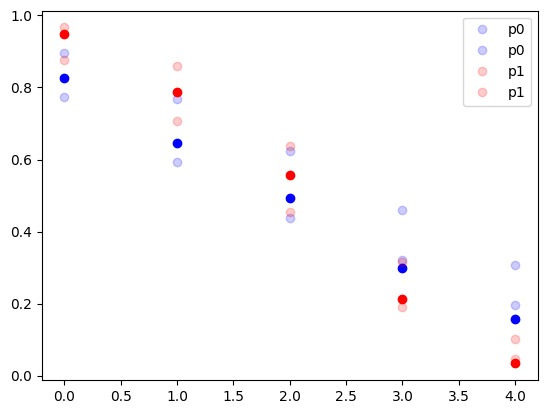

mean shape 1.7599999999999993
mean scale 11.72
49.0
mean time draws 10.837649831616519
cens mean 68.07
0.8925
[ 3  6  9 14 19]
[ 3.  6.  9. 14. 19.]
w  [1. 2. 4.]
sum
15.0
(46, 1)
32.0
(38, 1)


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 100 tune and 200 draw iterations (1_200 + 2_400 draws total) took 6 seconds.
Sampling: [f]


Output()

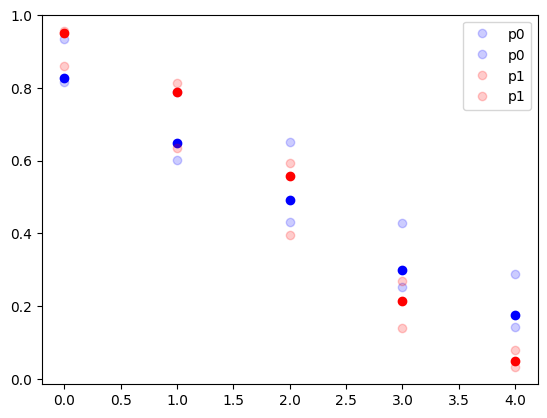

mean shape 1.6774999999999998
mean scale 11.76125
49.0
mean time draws 11.328282582789283
cens mean 69.8225
0.8575
[ 3  5  9 14 20]
[ 3.  5.  9. 14. 20.]
w  [1. 4.]
sum
19.0
(48, 1)
29.0
(39, 1)


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 100 tune and 200 draw iterations (1_200 + 2_400 draws total) took 6 seconds.
Sampling: [f]


Output()

...

mean shape 1.7424999999999995
mean scale 11.72875
49.0
mean time draws 10.431878811571817
cens mean 69.5175
0.8725
[ 3  6  9 14 19]
[ 3.  6.  9. 14. 19.]
w  [1. 3. 7.]
sum
23.0
(44, 1)
34.0
(42, 1)


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 100 tune and 200 draw iterations (1_200 + 2_400 draws total) took 7 seconds.
Sampling: [f]


Output()

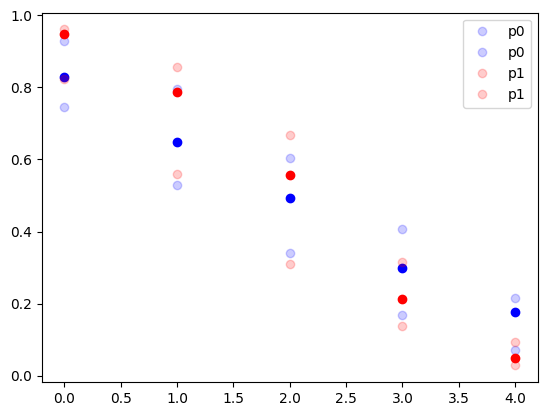

mean shape 1.6749999999999994
mean scale 11.7625
49.0
mean time draws 10.091593995668966
cens mean 72.745
0.8575
[ 3  5  9 14 20]
[ 3.  5.  9. 14. 20.]
w  [1. 3. 9.]
sum
20.0
(42, 1)
30.0
(32, 1)


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 100 tune and 200 draw iterations (1_200 + 2_400 draws total) took 7 seconds.
Sampling: [f]


Output()

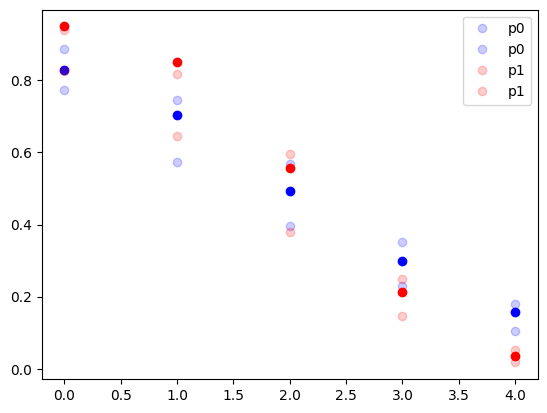

mean shape 1.6824999999999994
mean scale 11.75875
49.0
mean time draws 10.55236591921271
cens mean 73.77
0.905
[ 3  5  9 14 20]
[ 3.  5.  9. 14. 20.]
w  [1. 3. 7.]
sum
23.0
(53, 1)
40.0
(44, 1)


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 100 tune and 200 draw iterations (1_200 + 2_400 draws total) took 7 seconds.
Sampling: [f]


Output()

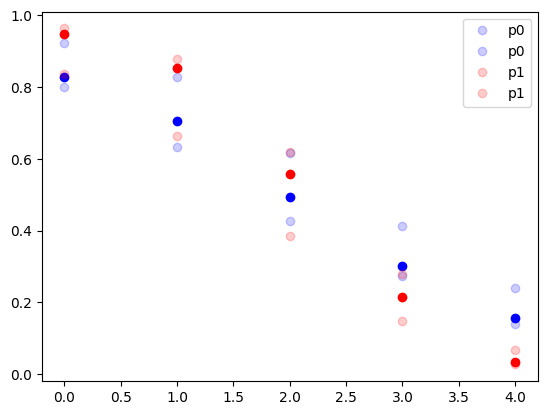

mean shape 1.7224999999999997
mean scale 11.73875
49.0
mean time draws 11.33503065460453
cens mean 73.265
0.87
[ 3  6  9 14 20]
[ 3.  6.  9. 14. 20.]
w  [1. 3. 5.]
sum
19.0
(59, 1)
35.0
(42, 1)


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 100 tune and 200 draw iterations (1_200 + 2_400 draws total) took 7 seconds.
Sampling: [f]


Output()

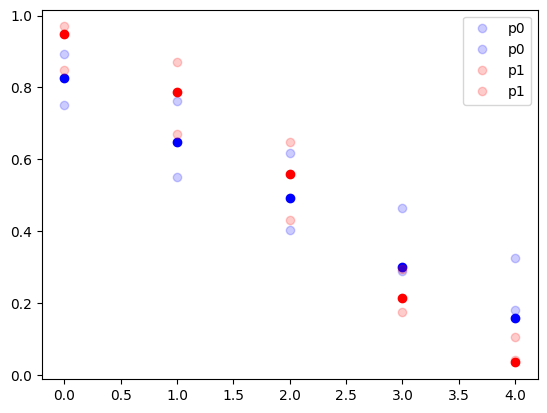

mean shape 1.7599999999999993
mean scale 11.72
49.0
mean time draws 10.837649831616519
cens mean 68.07
0.8925
[ 3  6  9 14 19]
[ 3.  6.  9. 14. 19.]
w  [1. 3. 7.]
sum
15.0
(46, 1)
32.0
(38, 1)


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 100 tune and 200 draw iterations (1_200 + 2_400 draws total) took 8 seconds.
Sampling: [f]


Output()

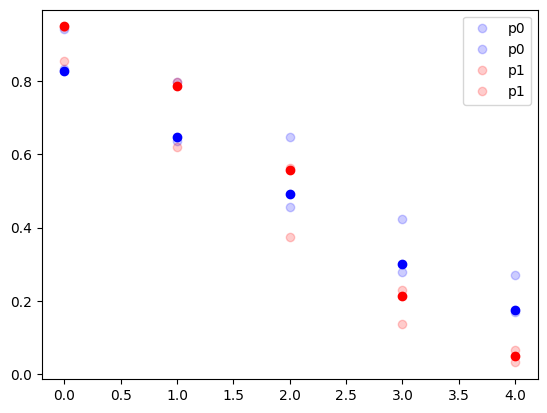

mean shape 1.6774999999999998
mean scale 11.76125
49.0
mean time draws 11.328282582789283
cens mean 69.8225
0.8575
[ 3  5  9 14 20]
[ 3.  5.  9. 14. 20.]
w  [1. 7.]
sum
19.0
(48, 1)
29.0
(39, 1)


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 100 tune and 200 draw iterations (1_200 + 2_400 draws total) took 6 seconds.
Sampling: [f]


Output()

...

mean shape 1.7424999999999995
mean scale 11.72875
49.0
mean time draws 10.431878811571817
cens mean 69.5175
0.8725
[ 3  6  9 14 19]
[ 3.  6.  9. 14. 19.]
w  [ 1.  6. 16.]
sum
23.0
(44, 1)
34.0
(42, 1)


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 100 tune and 200 draw iterations (1_200 + 2_400 draws total) took 6 seconds.
Sampling: [f]


Output()

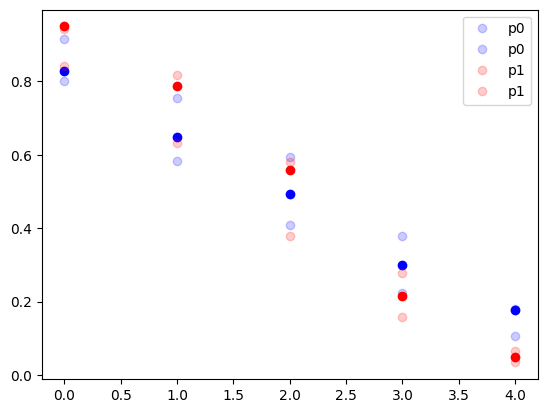

mean shape 1.6749999999999994
mean scale 11.7625
49.0
mean time draws 10.091593995668966
cens mean 72.745
0.8575
[ 3  5  9 14 20]
[ 3.  5.  9. 14. 20.]
w  [ 1.  6. 21.]
sum
20.0
(42, 1)
30.0
(32, 1)


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 100 tune and 200 draw iterations (1_200 + 2_400 draws total) took 6 seconds.
Sampling: [f]


Output()

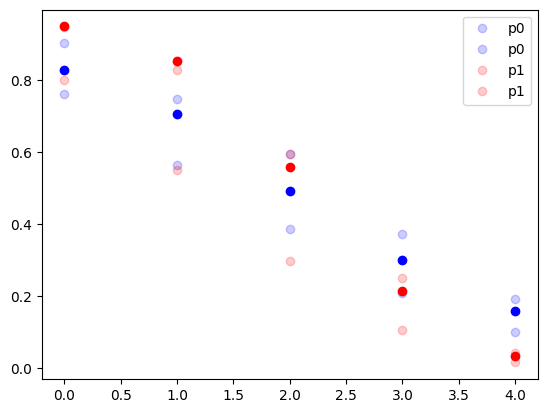

mean shape 1.6824999999999994
mean scale 11.75875
49.0
mean time draws 10.55236591921271
cens mean 73.77
0.905
[ 3  5  9 14 20]
[ 3.  5.  9. 14. 20.]
w  [ 1.  6. 16.]
sum
23.0
(53, 1)
40.0
(44, 1)


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 100 tune and 200 draw iterations (1_200 + 2_400 draws total) took 6 seconds.
Sampling: [f]


Output()

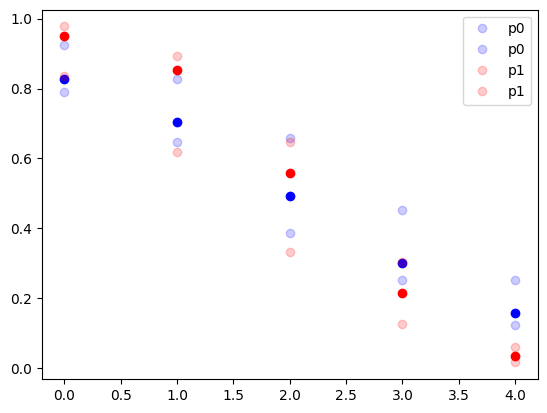

mean shape 1.7224999999999997
mean scale 11.73875
49.0
mean time draws 11.33503065460453
cens mean 73.265
0.87
[ 3  6  9 14 20]
[ 3.  6.  9. 14. 20.]
w  [ 1.  6. 11.]
sum
19.0
(59, 1)
35.0
(42, 1)


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 100 tune and 200 draw iterations (1_200 + 2_400 draws total) took 7 seconds.
Sampling: [f]


Output()

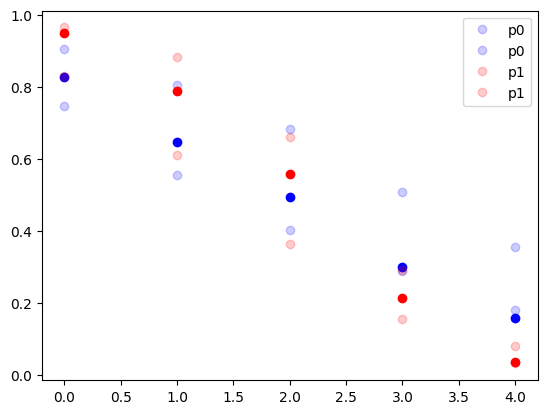

mean shape 1.7599999999999993
mean scale 11.72
49.0
mean time draws 10.837649831616519
cens mean 68.07
0.8925
[ 3  6  9 14 19]
[ 3.  6.  9. 14. 19.]
w  [ 1.  6. 16.]
sum
15.0
(46, 1)
32.0
(38, 1)


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 100 tune and 200 draw iterations (1_200 + 2_400 draws total) took 7 seconds.
Sampling: [f]


Output()

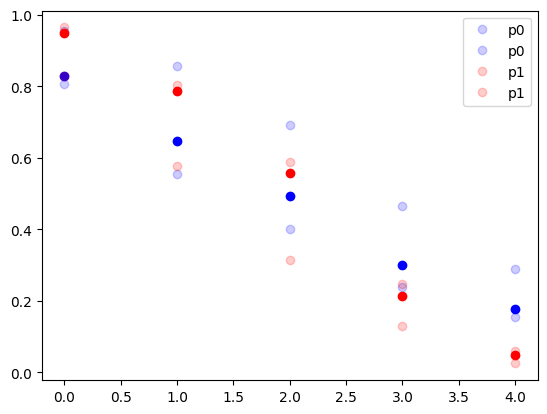

mean shape 1.6774999999999998
mean scale 11.76125
49.0
mean time draws 11.328282582789283
cens mean 69.8225
0.8575
[ 3  5  9 14 20]
[ 3.  5.  9. 14. 20.]
w  [ 1. 16.]
sum
19.0
(48, 1)
29.0
(39, 1)


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 100 tune and 200 draw iterations (1_200 + 2_400 draws total) took 7 seconds.
Sampling: [f]


Output()

...

mean shape 1.7424999999999995
mean scale 11.72875
49.0
mean time draws 10.431878811571817
cens mean 69.5175
0.8725
[ 3  6  9 14 19]
[ 3.  6.  9. 14. 19.]
w  [ 1. 11. 31.]
sum
23.0
(44, 1)
34.0
(42, 1)


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 100 tune and 200 draw iterations (1_200 + 2_400 draws total) took 7 seconds.
Sampling: [f]


Output()

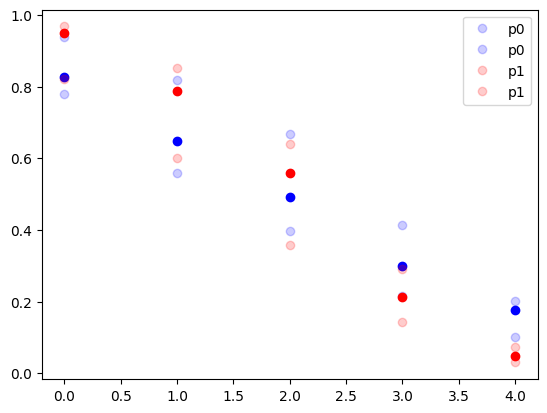

mean shape 1.6749999999999994
mean scale 11.7625
49.0
mean time draws 10.091593995668966
cens mean 72.745
0.8575
[ 3  5  9 14 20]
[ 3.  5.  9. 14. 20.]
w  [ 1. 11. 41.]
sum
20.0
(42, 1)
30.0
(32, 1)


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 100 tune and 200 draw iterations (1_200 + 2_400 draws total) took 7 seconds.
Sampling: [f]


Output()

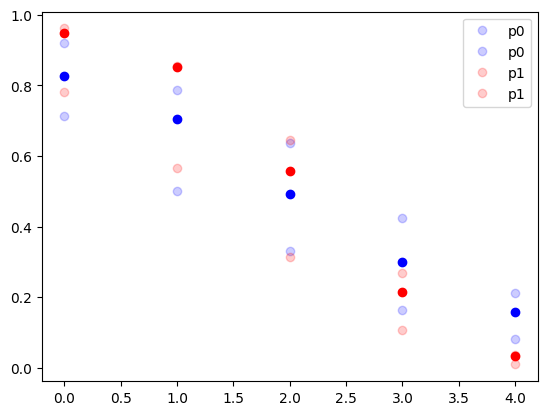

mean shape 1.6824999999999994
mean scale 11.75875
49.0
mean time draws 10.55236591921271
cens mean 73.77
0.905
[ 3  5  9 14 20]
[ 3.  5.  9. 14. 20.]
w  [ 1. 11. 31.]
sum
23.0
(53, 1)
40.0
(44, 1)


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 100 tune and 200 draw iterations (1_200 + 2_400 draws total) took 6 seconds.
Sampling: [f]


Output()

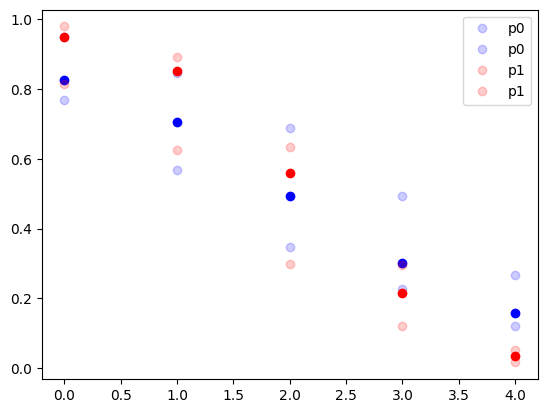

mean shape 1.7224999999999997
mean scale 11.73875
49.0
mean time draws 11.33503065460453
cens mean 73.265
0.87
[ 3  6  9 14 20]
[ 3.  6.  9. 14. 20.]
w  [ 1. 11. 21.]
sum
19.0
(59, 1)
35.0
(42, 1)


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 100 tune and 200 draw iterations (1_200 + 2_400 draws total) took 6 seconds.
Sampling: [f]


Output()

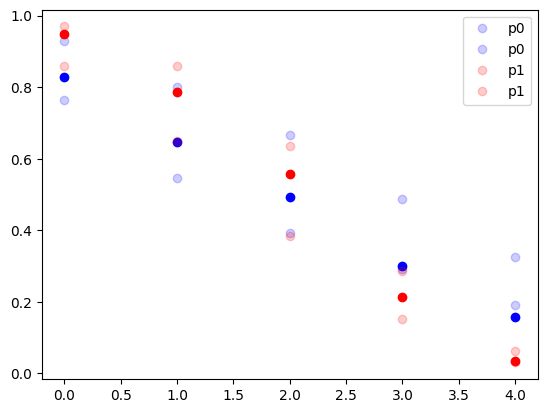

mean shape 1.7599999999999993
mean scale 11.72
49.0
mean time draws 10.837649831616519
cens mean 68.07
0.8925
[ 3  6  9 14 19]
[ 3.  6.  9. 14. 19.]
w  [ 1. 11. 31.]
sum
15.0
(46, 1)
32.0
(38, 1)


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 100 tune and 200 draw iterations (1_200 + 2_400 draws total) took 6 seconds.
Sampling: [f]


Output()

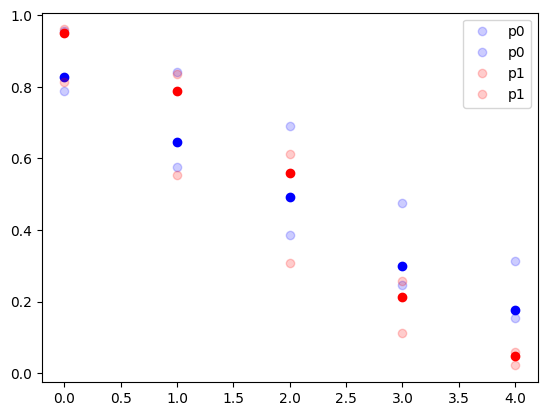

mean shape 1.6774999999999998
mean scale 11.76125
49.0
mean time draws 11.328282582789283
cens mean 69.8225
0.8575
[ 3  5  9 14 20]
[ 3.  5.  9. 14. 20.]
w  [ 1. 31.]
sum
19.0
(48, 1)
29.0
(39, 1)


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 100 tune and 200 draw iterations (1_200 + 2_400 draws total) took 6 seconds.
Sampling: [f]


Output()

...

mean shape 1.7424999999999995
mean scale 11.72875
49.0
mean time draws 10.431878811571817
cens mean 69.5175
0.8725
[ 3  6  9 14 19]
[ 3.  6.  9. 14. 19.]
w  [ 1. 21. 61.]
sum
23.0
(44, 1)
34.0
(42, 1)


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 100 tune and 200 draw iterations (1_200 + 2_400 draws total) took 6 seconds.
Sampling: [f]


Output()

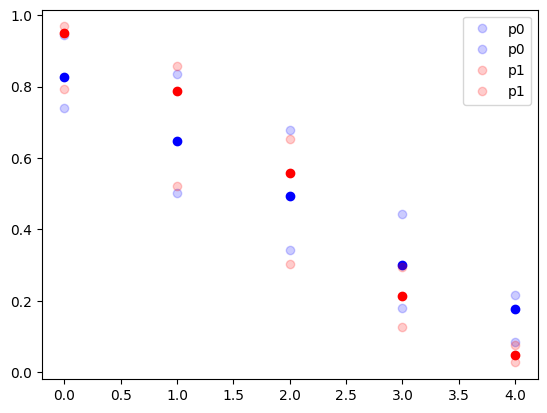

mean shape 1.6749999999999994
mean scale 11.7625
49.0
mean time draws 10.091593995668966
cens mean 72.745
0.8575
[ 3  5  9 14 20]
[ 3.  5.  9. 14. 20.]
w  [ 1. 21. 81.]
sum
20.0
(42, 1)
30.0
(32, 1)


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 100 tune and 200 draw iterations (1_200 + 2_400 draws total) took 6 seconds.
Sampling: [f]


Output()

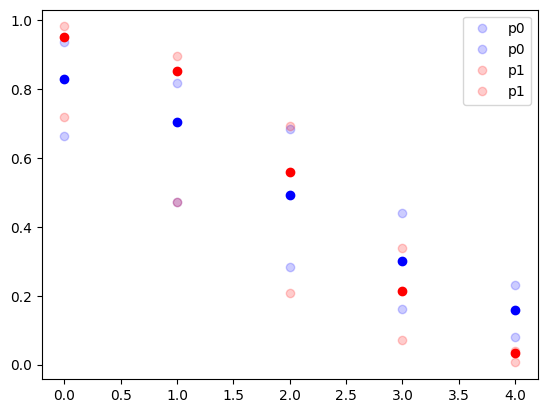

mean shape 1.6824999999999994
mean scale 11.75875
49.0
mean time draws 10.55236591921271
cens mean 73.77
0.905
[ 3  5  9 14 20]
[ 3.  5.  9. 14. 20.]
w  [ 1. 21. 61.]
sum
23.0
(53, 1)
40.0
(44, 1)


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 100 tune and 200 draw iterations (1_200 + 2_400 draws total) took 7 seconds.
Sampling: [f]


Output()

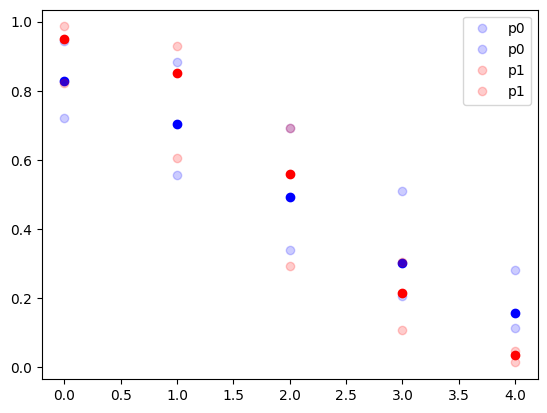

mean shape 1.7224999999999997
mean scale 11.73875
49.0
mean time draws 11.33503065460453
cens mean 73.265
0.87
[ 3  6  9 14 20]
[ 3.  6.  9. 14. 20.]
w  [ 1. 21. 41.]
sum
19.0
(59, 1)
35.0
(42, 1)


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 100 tune and 200 draw iterations (1_200 + 2_400 draws total) took 6 seconds.
Sampling: [f]


Output()

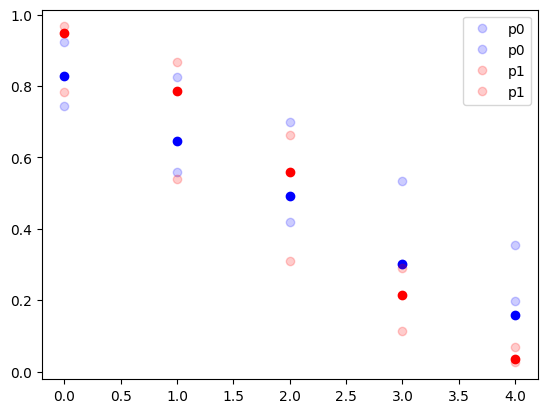

mean shape 1.7599999999999993
mean scale 11.72
49.0
mean time draws 10.837649831616519
cens mean 68.07
0.8925
[ 3  6  9 14 19]
[ 3.  6.  9. 14. 19.]
w  [ 1. 21. 61.]
sum
15.0
(46, 1)
32.0
(38, 1)


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 100 tune and 200 draw iterations (1_200 + 2_400 draws total) took 6 seconds.
Sampling: [f]


Output()

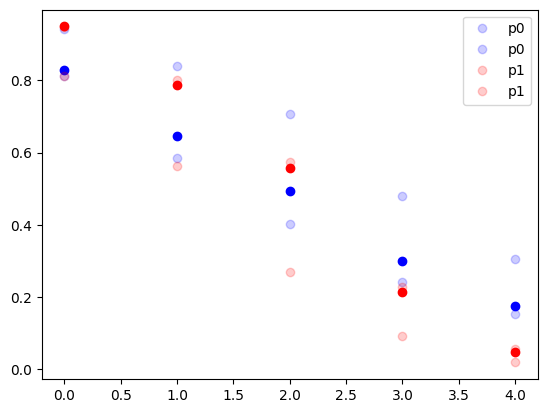

mean shape 1.6774999999999998
mean scale 11.76125
49.0
mean time draws 11.328282582789283
cens mean 69.8225
0.8575
[ 3  5  9 14 20]
[ 3.  5.  9. 14. 20.]
w  [ 1. 61.]
sum
19.0
(48, 1)
29.0
(39, 1)


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 100 tune and 200 draw iterations (1_200 + 2_400 draws total) took 6 seconds.
Sampling: [f]


Output()

...

mean shape 1.7224999999999995
mean scale 11.73875
49.0
mean time draws 11.774968315888314
cens mean 69.46
0.8675
[ 3  6  9 14 20]
[ 3.  6.  9. 14. 20.]
w  [ 1. 61.]
sum
29.0
(65, 1)
30.0
(35, 1)


/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 100 tune and 200 draw iterations (1_200 + 2_400 draws total) took 6 seconds.
Sampling: [f]


Output()

In [6]:

dfout0 =pd.DataFrame()
for t in [True]:
    for n in [400]:
        for w in [1, 2, 5, 10, 20]:
            dfout = pd.DataFrame()
            for seed in range(50):
                sv_true_r0, sv_true_r1, pb_sv, k_sv0, k_sv1 = runner(seed, n, adj_weights=t, w_factor=w)
                dfres = pd.DataFrame(np.array([
                rmse(sv_true_r0, pb_sv[0][1]),
                rmse(sv_true_r1, pb_sv[1][1]),
                rmse(sv_true_r0, k_sv0[0]),
                rmse(sv_true_r1, k_sv1[0]),
                bias(sv_true_r0, pb_sv[0][1]),
                bias(sv_true_r1, pb_sv[1][1]),
                bias(sv_true_r0, k_sv0[0]),
                bias(sv_true_r1, k_sv1[0]),
                *coverage(sv_true_r0, pb_sv[0][2]),
                *coverage(sv_true_r1, pb_sv[1][2]),
                *coverage(sv_true_r0, k_sv0[1]),
                *coverage(sv_true_r1, k_sv1[1])
                ])).T
                dfres.columns=[
                        "rmse_p0", "rmse_p1", "rmse_k0", "rmse_k1",
                        "bias_p0", "bias_p1", "bias_k0", "bias_k1",
                        *["cov_p0"+str(i) for i in [1,2,3,4,5]],
                        *["cov_p1"+str(i) for i in [1,2,3,4,5]],
                        *["cov_k0"+str(i) for i in [1,2,3,4,5]],
                        *["cov_k1"+str(i) for i in [1,2,3,4,5]]
                    ]

                dfout = pd.concat([dfout, dfres])
                if seed < 5: 
                    plt.figure()
                    plt.plot(pb_sv[0][2].T, "o", color="blue", alpha=0.2, label="p0")
                    plt.plot(sv_true_r0,"o",color="blue")
                    plt.plot(pb_sv[1][2].T, "o", color="red", alpha=0.2, label="p1")
                    plt.plot(sv_true_r1,"o", color= "red")
                    plt.legend()
                    plt.show() 

            tmp = dfout.mean(axis=0)
            tmp=tmp.to_frame().T
            tmp["n"] = n
            tmp["weight_adj"] = t
            tmp["w_factor"] = w
            dfout0 = pd.concat([dfout0, tmp],axis=0)
        


In [8]:
pd.set_option("display.max_columns", None)
dfout0

,rmse_p0,rmse_p1,rmse_k0,rmse_k1,bias_p0,bias_p1,bias_k0,bias_k1,cov_p01,cov_p02,cov_p03,cov_p04,cov_p05,cov_p11,cov_p12,cov_p13,cov_p14,cov_p15,cov_k01,cov_k02,cov_k03,cov_k04,cov_k05,cov_k11,cov_k12,cov_k13,cov_k14,cov_k15,n,weight_adj,w_factor
0,0.028345,0.036517,0.029723,0.026451,-0.011087,0.017668,-0.004186,-0.007943,0.98,0.98,0.98,0.96,0.88,0.86,0.84,0.96,1.00,0.52,0.92,0.9,0.98,0.94,0.94,0.96,0.94,0.96,0.96,0.98,400,True,1
0,0.030155,0.039078,0.029723,0.026451,-0.014535,0.023646,-0.004186,-0.007943,0.96,0.98,0.98,0.98,0.84,0.82,0.84,0.94,1.00,0.62,0.92,0.9,0.98,0.94,0.94,0.96,0.94,0.96,0.96,0.98,400,True,2
0,0.033620,0.044480,0.029723,0.026451,-0.020532,0.032008,-0.004186,-0.007943,0.98,0.98,0.98,0.98,0.84,0.94,0.92,0.98,0.96,0.78,0.92,0.9,0.98,0.94,0.94,0.96,0.94,0.96,0.96,0.98,400,True,5
0,0.036839,0.050955,0.029723,0.026451,-0.022910,0.039244,-0.004186,-0.007943,1.00,1.00,1.00,1.00,0.88,0.92,0.92,0.94,0.94,0.82,0.92,0.9,0.98,0.94,0.94,0.96,0.94,0.96,0.96,0.98,400,True,10
0,0.037931,0.057041,0.029723,0.026451,-0.023954,0.044964,-0.004186,-0.007943,1.00,1.00,1.00,0.98,0.90,0.94,0.98,1.00,0.96,0.90,0.92,0.9,0.98,0.94,0.94,0.96,0.94,0.96,0.96,0.98,400,True,20
